<h1 align="center">ДЗ 2.1: SCD2</h1>

## Запускаем спарк сессию

In [1]:
from pyspark.sql import SparkSession

In [2]:
spark = (
    SparkSession.builder
    .appName("hw21-SCD2")
    .master("spark://spark-master:7077")
    .config("spark.driver.host", "scd2-jupyter")
    .getOrCreate()
)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/05 12:07:44 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Подключаемся к S3 (RustFS)

In [3]:
# Параметры подключения к RustFS
S3_ENDPOINT = "http://rustfs:9000"
S3_ACCESS_KEY = "scd2admin"
S3_SECRET_KEY = "scd2-secret-2026"
S3_BUCKET = "scd2-data"

# Получаем конфигурацию Hadoop из SparkContext
hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()

# Настройки S3A
hadoop_conf.set("fs.s3a.endpoint", S3_ENDPOINT)
hadoop_conf.set("fs.s3a.access.key", S3_ACCESS_KEY)
hadoop_conf.set("fs.s3a.secret.key", S3_SECRET_KEY)
hadoop_conf.set(
    "fs.s3a.aws.credentials.provider",
    "org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider"
)
hadoop_conf.set("fs.s3a.path.style.access", "true")
hadoop_conf.set("fs.s3a.connection.ssl.enabled", "false")
hadoop_conf.set(
    "fs.s3a.impl",
    "org.apache.hadoop.fs.s3a.S3AFileSystem"
)

print("Конфигурация S3A установлена")

Конфигурация S3A установлена


In [4]:
from py4j.java_gateway import java_import

In [5]:
java_import(spark.sparkContext._jvm, "org.apache.hadoop.fs.Path")
path = spark.sparkContext._jvm.Path(f"s3a://{S3_BUCKET}/")
fs = path.getFileSystem(hadoop_conf)

26/11/05 12:07:46 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


## Генерация данных

In [6]:
import random

In [7]:
random.seed(2501)
ROWS = random.randint(5000, 7000)
print(f"Количество строк для генерации: {ROWS}")

Количество строк для генерации: 5365


Генерируем данные:
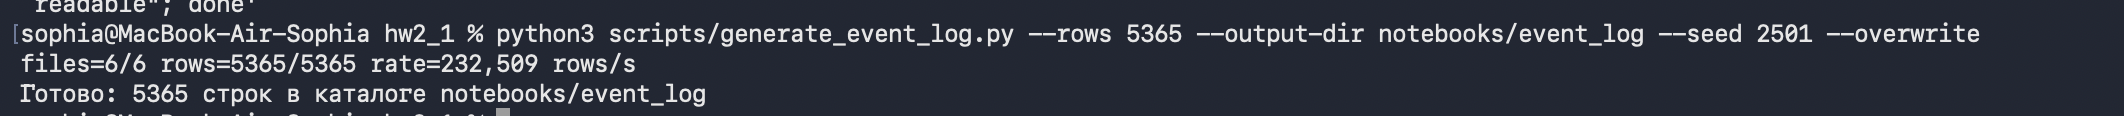

In [8]:
ls -lh event_log/

total 436K
-rw-r--r-- 1 root root 79K Nov  4 18:47 events_00001.csv
-rw-r--r-- 1 root root 79K Nov  4 18:47 events_00002.csv
-rw-r--r-- 1 root root 79K Nov  4 18:47 events_00003.csv
-rw-r--r-- 1 root root 79K Nov  4 18:47 events_00004.csv
-rw-r--r-- 1 root root 79K Nov  4 18:47 events_00005.csv
-rw-r--r-- 1 root root 29K Nov  4 18:47 events_00006.csv
-rw-r--r-- 1 root root 433 Nov  4 18:47 _manifest.json


In [9]:
cat event_log/_manifest.json

{
  "format": "csv",
  "columns": [
    "event_time",
    "user_id",
    "user_fio",
    "user_email",
    "user_login"
  ],
  "total_rows": 5365,
  "rows_per_file": 1000,
  "file_count": 6,
  "user_count": 268,
  "user_id_start": 1,
  "change_probability": 0.01,
  "applied_profile_changes": 46,
  "seed": 2501,
  "first_event_time": "2026-09-01T00:00:01Z",
  "last_event_time": "2026-09-01T02:59:20Z",
  "elapsed_seconds": 0.023
}


## Загрузим данные в S3

In [10]:
import os

In [11]:
local_dir = "/home/jupyter/work/event_log"
s3_dir = f"s3a://{S3_BUCKET}/source/"
s3_path = spark.sparkContext._jvm.Path(s3_dir)
fs.delete(s3_path, True)
fs.mkdirs(s3_path)

for f in sorted(os.listdir(local_dir)):
    if f.endswith(".csv"):
        local_path = spark.sparkContext._jvm.Path(f"file:{local_dir}/{f}")
        target_path = spark.sparkContext._jvm.Path(f"{s3_dir}{f}")
        fs.copyFromLocalFile(False, True, local_path, target_path)
        print(f"Загружен файл: {f}")

Загружен файл: events_00001.csv
Загружен файл: events_00002.csv
Загружен файл: events_00003.csv
Загружен файл: events_00004.csv
Загружен файл: events_00005.csv
Загружен файл: events_00006.csv


## Читаем из S3

In [12]:
events_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(f"s3a://{S3_BUCKET}/source/*.csv")
)

In [13]:
print("Количество событий:", events_df.count())

Количество событий: 5365


In [14]:
events_df.show(truncate=False)

+-------------------+-------+------------------+------------------------------------+------------+
|event_time         |user_id|user_fio          |user_email                          |user_login  |
+-------------------+-------+------------------+------------------------------------+------------+
|2026-09-01 01:06:08|82     |Amelia Jones      |amelia.jones.82@inbox.example       |ajones82    |
|2026-09-01 01:06:11|123    |Joseph Hughes     |joseph.hughes.123@webmail.example   |jhughes123  |
|2026-09-01 01:06:12|130    |Jack Sanchez      |jack.sanchez.130@inbox.example      |jsanchez130 |
|2026-09-01 01:06:14|127    |Elizabeth Campbell|elizabeth.campbell.127@inbox.example|ecampbell127|
|2026-09-01 01:06:16|35     |Austin Hall       |austin.hall.35@post.example         |ahall35     |
|2026-09-01 01:06:18|253    |Elizabeth Brooks  |elizabeth.brooks.253@inbox.example  |ebrooks253  |
|2026-09-01 01:06:20|17     |Noah Clark        |noah.clark.17@mail.example          |nclark17    |
|2026-09-0

## Cборка SCD2

Правила сборки, согласно тз:
- События каждого user_id необходимо упорядочить по event_time.
- Новая версия создаётся только при изменении user_fio, user_email или user_login.
- Интервал версии полуоткрытый: [valid_from, valid_to).
- У актуальной версии valid_to равен NULL, а is_current равен true.
- У каждого пользователя должна быть ровно одна актуальная версия; интервалы не
должны пересекаться.
- Повторный запуск на тех же данных должен давать тот же результат без дублей.

Для каждого юзера формируем окно по времени:

In [15]:
from pyspark.sql.window import Window

In [16]:
w = Window.partitionBy("user_id").orderBy("event_time")

Для каждого пользователя сохраняем информацию о профиле из прошлого события:

In [17]:
from pyspark.sql import functions as F

In [18]:
events_prev = events_df.select(
    "*",
    F.lag("user_fio").over(w).alias("prev_user_fio"),
    F.lag("user_email").over(w).alias("prev_user_email"),
    F.lag("user_login").over(w).alias("prev_user_login"),
)

In [19]:
events_prev.show()

+-------------------+-------+-------------+--------------------+----------+-------------+--------------------+---------------+
|         event_time|user_id|     user_fio|          user_email|user_login|prev_user_fio|     prev_user_email|prev_user_login|
+-------------------+-------+-------------+--------------------+----------+-------------+--------------------+---------------+
|2026-09-01 00:45:17|      1|Jacob Ramirez|jacob.ramirez.1@w...| jramirez1|         NULL|                NULL|           NULL|
|2026-09-01 00:51:13|      1|Jacob Ramirez|jacob.ramirez.1@w...| jramirez1|Jacob Ramirez|jacob.ramirez.1@w...|      jramirez1|
|2026-09-01 00:59:31|      1|Jacob Ramirez|jacob.ramirez.1@w...| jramirez1|Jacob Ramirez|jacob.ramirez.1@w...|      jramirez1|
|2026-09-01 01:30:56|      1|Jacob Ramirez|jacob.ramirez.1@w...| jramirez1|Jacob Ramirez|jacob.ramirez.1@w...|      jramirez1|
|2026-09-01 01:41:48|      1|Jacob Ramirez|jacob.ramirez.1@w...| jramirez1|Jacob Ramirez|jacob.ramirez.1@w...| 

Отфильтровываем только те события, в которых менялось состояние профиля, те изменилось либо фио, либо почта, либо логин:

In [20]:
users_history = events_prev.filter(
    F.col("prev_user_fio").isNull() |
    (F.col("user_fio") != F.col("prev_user_fio")) |
    (F.col("user_email") != F.col("prev_user_email")) |
    (F.col("user_login") != F.col("prev_user_login"))
).drop("prev_user_fio", "prev_user_email", "prev_user_login")

In [21]:
users_history.show(truncate=False)

+-------------------+-------+----------------+---------------------------------+------------+
|event_time         |user_id|user_fio        |user_email                       |user_login  |
+-------------------+-------+----------------+---------------------------------+------------+
|2026-09-01 00:45:17|1      |Jacob Ramirez   |jacob.ramirez.1@webmail.example  |jramirez1   |
|2026-09-01 00:10:14|2      |Madison Diaz    |madison.diaz.2@mail.example      |mdiaz2      |
|2026-09-01 00:06:56|3      |Zoe Foster      |zoe.foster.3@inbox.example       |zfoster3    |
|2026-09-01 00:05:55|4      |Michael Kelly   |michael.kelly.4@post.example     |mkelly4     |
|2026-09-01 00:15:00|5      |Allison Brown   |allison.brown.5@example.com      |abrown5     |
|2026-09-01 00:08:55|6      |Joshua Roberts  |joshua.roberts.6@mail.example    |jroberts6   |
|2026-09-01 00:10:29|7      |Caroline Kelly  |caroline.kelly.7@mail.example    |ckelly7     |
|2026-09-01 00:10:55|7      |Caroline Kelly  |caroline.kelly

Для каждого события добавляем информацию про его временной интервал, а также флаг актуальности:

In [22]:
users_history = (
    users_history
    .withColumn("valid_from", F.col("event_time"))
    .withColumn("valid_to", F.lead("event_time").over(w))
    .withColumn("is_current", F.col("valid_to").isNull())
    .drop("event_time")
)

In [23]:
users_history.show()

+-------+----------------+--------------------+------------+-------------------+-------------------+----------+
|user_id|        user_fio|          user_email|  user_login|         valid_from|           valid_to|is_current|
+-------+----------------+--------------------+------------+-------------------+-------------------+----------+
|      1|   Jacob Ramirez|jacob.ramirez.1@w...|   jramirez1|2026-09-01 00:45:17|               NULL|      true|
|      2|    Madison Diaz|madison.diaz.2@ma...|      mdiaz2|2026-09-01 00:10:14|               NULL|      true|
|      3|      Zoe Foster|zoe.foster.3@inbo...|    zfoster3|2026-09-01 00:06:56|               NULL|      true|
|      4|   Michael Kelly|michael.kelly.4@p...|     mkelly4|2026-09-01 00:05:55|               NULL|      true|
|      5|   Allison Brown|allison.brown.5@e...|     abrown5|2026-09-01 00:15:00|               NULL|      true|
|      6|  Joshua Roberts|joshua.roberts.6@...|   jroberts6|2026-09-01 00:08:55|               NULL|    

Количество строк в полученной scd2 таблицы:

In [24]:
print("Всего версий:", users_history.count())

Всего версий: 314


Проверяем, что каждому пользователю соответствует 1 актуальная версия:

In [25]:
print("Количество пользователей:", users_history.select("user_id").distinct().count())
print("Количество актуальных версий:",users_history.filter(F.col("is_current")).count())

Количество пользователей: 268
Количество актуальных версий: 268


Пример: События для юзера 7

In [26]:
users_history.filter(F.col("user_id") == 7).show(truncate=False)

+-------+--------------+-----------------------------+----------+-------------------+-------------------+----------+
|user_id|user_fio      |user_email                   |user_login|valid_from         |valid_to           |is_current|
+-------+--------------+-----------------------------+----------+-------------------+-------------------+----------+
|7      |Caroline Kelly|caroline.kelly.7@mail.example|ckelly7   |2026-09-01 00:10:29|2026-09-01 00:10:55|false     |
|7      |Caroline Kelly|caroline.kelly.7@mail.example|ckelly7r1 |2026-09-01 00:10:55|NULL               |true      |
+-------+--------------+-----------------------------+----------+-------------------+-------------------+----------+



### Соберем всю сборку SCD2 в одну функцию:

In [27]:
def build_scd2(events_df=events_df):
    w = Window.partitionBy("user_id").orderBy("event_time")
    events_prev = events_df.select(
        "*",
        F.lag("user_fio").over(w).alias("prev_user_fio"),
        F.lag("user_email").over(w).alias("prev_user_email"),
        F.lag("user_login").over(w).alias("prev_user_login"),
    )
    users_history = events_prev.filter(
        F.col("prev_user_fio").isNull() |
        (F.col("user_fio") != F.col("prev_user_fio")) |
        (F.col("user_email") != F.col("prev_user_email")) |
        (F.col("user_login") != F.col("prev_user_login"))
    ).drop("prev_user_fio", "prev_user_email", "prev_user_login")
    users_history = (
        users_history
        .withColumn("valid_from", F.col("event_time"))
        .withColumn("valid_to", F.lead("event_time").over(w))
        .withColumn("is_current", F.col("valid_to").isNull())
        .drop("event_time")
    )
    return users_history

### Проверка на идемпотентность:

In [28]:
users_history2 = build_scd2()
print(users_history.exceptAll(users_history2).count() == 0 and users_history2.exceptAll(users_history).count() == 0)

True


In [29]:
uh1 = build_scd2()
uh2 = build_scd2()
print(uh1.exceptAll(uh2).count() == 0 and uh2.exceptAll(uh1).count() == 0)

True


Cохраним результат `users_history` в целевую таблицу в S3:

In [30]:
users_history.write.mode("overwrite").parquet(f"s3a://{S3_BUCKET}/scd2/users_history/")

## Аналитические запросы

Загружаем данные в спарк:

In [31]:
loaded_history = spark.read.parquet(f"s3a://{S3_BUCKET}/scd2/users_history/")
loaded_history.show(truncate=False)

+-------+----------------+---------------------------------+------------+-------------------+-------------------+----------+
|user_id|user_fio        |user_email                       |user_login  |valid_from         |valid_to           |is_current|
+-------+----------------+---------------------------------+------------+-------------------+-------------------+----------+
|1      |Jacob Ramirez   |jacob.ramirez.1@webmail.example  |jramirez1   |2026-09-01 00:45:17|NULL               |true      |
|2      |Madison Diaz    |madison.diaz.2@mail.example      |mdiaz2      |2026-09-01 00:10:14|NULL               |true      |
|3      |Zoe Foster      |zoe.foster.3@inbox.example       |zfoster3    |2026-09-01 00:06:56|NULL               |true      |
|4      |Michael Kelly   |michael.kelly.4@post.example     |mkelly4     |2026-09-01 00:05:55|NULL               |true      |
|5      |Allison Brown   |allison.brown.5@example.com      |abrown5     |2026-09-01 00:15:00|NULL               |true      |


### 1) Количество строк в полученной SCD2 таблице:

In [32]:
loaded_history.count()

314

Через sql запрос:

In [33]:
loaded_history.createOrReplaceTempView("lh_view")
spark.sql("SELECT COUNT(*) AS cnt FROM lh_view").show()

+---+
|cnt|
+---+
|314|
+---+



Совпадает с тем, что было до загрузки в S3:

In [34]:
users_history.count()

314

### 2) Параметризованный запрос, который находит активный user_login пользователя X на дату и время Y:

Через агрегацию df:

In [35]:
def actual_login(df, user_id, ts):
    return df.filter((F.col("user_id") == user_id) & (F.lit(ts) >= F.col("valid_from")) &
        (F.col("valid_to").isNull() | (F.lit(ts) < F.col("valid_to")))).select("user_login")

Через sql запрос:

In [36]:
def actual_login_sql(user_id, ts):
    query = """
    SELECT user_login
    FROM lh_view
    WHERE user_id = :id
        AND CAST(:ts AS TIMESTAMP) >= valid_from
        AND (valid_to IS NULL OR CAST(:ts AS TIMESTAMP) < valid_to)
    """
    return spark.sql(query, args={"id": user_id, "ts": ts})

### Тесты

Проверим несколько кейсов на примере юзера 9, который несколько раз менял свое состояние:

На момент времени 2026-09-01 00:00:00 для юзера 9 нет активного состояния профиля, значит запрос должен вывести пустую строку:

In [37]:
actual_login(loaded_history, user_id=9, ts="2026-09-01 00:00:00").show()

+----------+
|user_login|
+----------+
+----------+



In [38]:
actual_login_sql(user_id=9, ts="2026-09-01 00:00:00").show()

+----------+
|user_login|
+----------+
+----------+



Верно

В момент времени 2026-09-01 00:07:03 был создан профиль юзера 9, активный user_login = iedwards9

In [39]:
actual_login(loaded_history, user_id=9, ts="2026-09-01 00:07:03").show()

+----------+
|user_login|
+----------+
| iedwards9|
+----------+



In [40]:
actual_login_sql(user_id=9, ts="2026-09-01 00:07:03").show()

+----------+
|user_login|
+----------+
| iedwards9|
+----------+



Верно

В момент времени 2026-09-01 01:47:35 состояния профиля юзера 9 было изменено, изменился user_fio на Chloe Parker, но user_login остался прежним

In [41]:
actual_login(loaded_history, user_id=9, ts="2026-09-01 01:47:35").show()

+----------+
|user_login|
+----------+
| iedwards9|
+----------+



In [42]:
actual_login_sql(user_id=9, ts="2026-09-01 01:47:35").show()

+----------+
|user_login|
+----------+
| iedwards9|
+----------+



Проверим, что фио, актуальное на момент 2026-09-01 01:47:35 изменилось c Isabella Edwards на Chloe Parker:

In [43]:
loaded_history.filter((F.col("user_id") == 9) & (F.lit("2026-09-01 01:47:34") >= F.col("valid_from")) &
        (F.col("valid_to").isNull() | (F.lit("2026-09-01 01:47:34") < F.col("valid_to")))).select("user_fio").show()

+----------------+
|        user_fio|
+----------------+
|Isabella Edwards|
+----------------+



In [44]:
loaded_history.filter((F.col("user_id") == 9) & (F.lit("2026-09-01 01:47:35") >= F.col("valid_from")) &
        (F.col("valid_to").isNull() | (F.lit("2026-09-01 01:47:35") < F.col("valid_to")))).select("user_fio").show()

+------------+
|    user_fio|
+------------+
|Chloe Parker|
+------------+



Верно

В момент времени 2026-09-01 01:53:21 состояние профиля вновь изменилось, почта стала chloe.parker.9.r2@webmail.example, user_login остался прежним 

In [45]:
actual_login(loaded_history, user_id=9, ts="2026-09-01 01:54:00").show()

+----------+
|user_login|
+----------+
| iedwards9|
+----------+



In [46]:
actual_login_sql(user_id=9, ts="2026-09-01 01:54:00").show()

+----------+
|user_login|
+----------+
| iedwards9|
+----------+



In [47]:
loaded_history.filter((F.col("user_id") == 9) & (F.lit("2026-09-01 01:50:00") >= F.col("valid_from")) &
        (F.col("valid_to").isNull() | (F.lit("2026-09-01 01:50:00") < F.col("valid_to")))).select("user_email").show(truncate=False)

+--------------------------------+
|user_email                      |
+--------------------------------+
|isabella.edwards.9@inbox.example|
+--------------------------------+



In [48]:
loaded_history.filter((F.col("user_id") == 9) & (F.lit("2026-09-01 01:55:00") >= F.col("valid_from")) &
        (F.col("valid_to").isNull() | (F.lit("2026-09-01 01:55:00") < F.col("valid_to")))).select("user_email").show(truncate=False)

+---------------------------------+
|user_email                       |
+---------------------------------+
|chloe.parker.9.r2@webmail.example|
+---------------------------------+



Все верно

Теперь протестим случай, когда менялся логин, например для юзера 7

На момент времени "2026-09-01 00:00:00" нет активного состояния профиля, значит запрос должен вывести пустую строку:

In [49]:
actual_login(loaded_history, user_id=7, ts="2026-09-01 00:00:00").show()

+----------+
|user_login|
+----------+
+----------+



In [50]:
actual_login_sql(user_id=7, ts="2026-09-01 00:00:00").show()

+----------+
|user_login|
+----------+
+----------+



Верно

В момент "2026-09-01 00:10:29" был создан профиль с логином ckelly7, он и должен быть активным на момент, например, "2026-09-01 00:10:35":

In [51]:
actual_login(loaded_history, user_id=7, ts="2026-09-01 00:10:35").show()

+----------+
|user_login|
+----------+
|   ckelly7|
+----------+



In [52]:
actual_login_sql(user_id=7, ts="2026-09-01 00:10:35").show()

+----------+
|user_login|
+----------+
|   ckelly7|
+----------+



В момент "2026-09-01 00:10:55" состояние профиля изменилось, новый логин ckelly7r1:

In [53]:
actual_login(loaded_history, user_id=7, ts="2026-09-01 00:10:55").show()

+----------+
|user_login|
+----------+
| ckelly7r1|
+----------+



In [54]:
actual_login_sql(user_id=7, ts="2026-09-01 00:10:55").show()

+----------+
|user_login|
+----------+
| ckelly7r1|
+----------+



Это финальное состояние профиля, в любой момент времени после этого изменения логин остается таким же:

In [55]:
actual_login(loaded_history, user_id=7, ts="2026-09-01 00:11:55").show()

+----------+
|user_login|
+----------+
| ckelly7r1|
+----------+



In [56]:
actual_login_sql(user_id=7, ts="2026-09-01 00:11:55").show()

+----------+
|user_login|
+----------+
| ckelly7r1|
+----------+



In [57]:
actual_login(users_history, user_id=7, ts="2027-09-01 00:10:55").show()

+----------+
|user_login|
+----------+
| ckelly7r1|
+----------+



In [58]:
actual_login_sql(user_id=7, ts="2027-09-01 00:10:55").show()

+----------+
|user_login|
+----------+
| ckelly7r1|
+----------+



Все верно